# Capitolo 12 — Predizione densa: maschere, profondità e flow

Arcangelo Distante e Cosimo Distante · **Computer Vision**

Non vengono addestrati o interrogati U-Net, DPT o RAFT. Target, errori e spostamenti sono sintetici. Le metriche verificano equazioni e convenzioni, senza produrre un benchmark di reti.

## Avvio in Google Colab o in locale

Aprire questo file in Colab e selezionare un runtime Python su CPU; non è richiesta una GPU. Usare **Esegui tutto** dall’inizio. Le dipendenze sono NumPy e Matplotlib, già normalmente presenti in Colab; in un ambiente locale installarle con `python -m pip install numpy matplotlib`.

I dati vengono costruiti nelle celle: non occorre caricare file, checkpoint o figure del libro. Per ripartire, riavviare il runtime ed eseguire tutte le celle in ordine. La cartella relativa `output_capitolo12` conserva JSON, CSV e figure; in Colab scaricarla prima di terminare la sessione. Le variabili intermedie non persistono dopo il riavvio.

Le istruzioni per Colab descrivono la procedura di avvio; non attribuiscono al servizio misure effettuate altrove.

In [1]:
from pathlib import Path
import json, platform
import numpy as np
import matplotlib.pyplot as plt

output = Path('output_capitolo12')
output.mkdir(exist_ok=True)
rng = np.random.default_rng(42)
plt.rcParams.update({'font.size': 11, 'figure.figsize': (7, 4)})
def salva_json(nome, dati):
    (output / nome).write_text(json.dumps(dati, indent=2, ensure_ascii=False,
        allow_nan=False, default=lambda v: np.asarray(v).tolist()), encoding='utf-8')
salva_json('ambiente.json', {'python': platform.python_version(), 'numpy': np.__version__,
                           'dispositivo': 'CPU', 'dati': 'sintetici autocontenuti'})
print('Output:', output)


Output: output_capitolo12


## A — Confusione e aggregazione

Le righe della matrice sono classi vere, le colonne classi predette. La classe foreground ha indice 1. Le maschere sono costruite in memoria e non richiedono immagini esterne.

{'confusione': array([[8, 2],
       [1, 5]]), 'IoU': array([0.72727273, 0.625     ]), 'Dice_foreground': np.float64(0.7692307692307693), 'mIoU': np.float64(0.6761363636363636), 'accuracy': np.float64(0.8125), 'media_IoU_immagini': np.float64(0.7), 'IoU_pooled': np.float64(0.8921568627450981)}


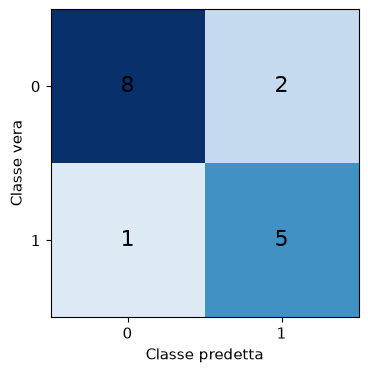

In [2]:
true = np.r_[np.zeros(10,dtype=int),np.ones(6,dtype=int)]
pred = np.r_[np.zeros(8,dtype=int),np.ones(2,dtype=int),0,np.ones(5,dtype=int)]
conf = np.bincount(2*true+pred,minlength=4).reshape(2,2)
tp = np.diag(conf); union = conf.sum(0)+conf.sum(1)-tp
ious = tp/union; dice = 2*tp[1]/(conf.sum(0)[1]+conf.sum(1)[1])
metriche = {'confusione':conf,'IoU':ious,'Dice_foreground':dice,
            'mIoU':ious.mean(),'accuracy':tp.sum()/conf.sum()}
micro_cases = np.array([[1,0,1],[90,10,0]])
metriche['media_IoU_immagini'] = np.mean(micro_cases[:,0]/micro_cases.sum(1))
metriche['IoU_pooled'] = micro_cases[:,0].sum()/micro_cases.sum()
assert np.isclose(metriche['mIoU'],119/176)
print(metriche); salva_json('segmentazione.json',metriche)
np.savetxt(output/'confusione.csv',conf,fmt='%d',delimiter=',',header='pred0,pred1',comments='')
fig,ax=plt.subplots(); ax.imshow(conf,cmap='Blues',vmin=0,vmax=8)
for i in range(2):
    for j in range(2): ax.text(j,i,str(conf[i,j]),ha='center',va='center',fontsize=16)
ax.set(xlabel='Classe predetta',ylabel='Classe vera',xticks=[0,1],yticks=[0,1]); fig.savefig(output/'confusione.png',dpi=180,bbox_inches='tight'); plt.show()


### Interpretazione

N12.A.1 — Ricavare TP, FP, FN e spiegare la differenza fra accuracy, IoU e Dice.

N12.A.2 — Quale immagine pesa maggiormente nella pooled? Quale convenzione servirebbe per un’unione vuota?

## B — Errore metrico e allineamento di scala

La profondità è positiva ed espressa in metri. L’allineamento usa il riferimento vero ed è quindi un altro protocollo, dichiarato separatamente.

In [3]:
z = np.array([1.,2.,4.]); zhat = 2*z
def depth_metrics(target, estimate):
    d = np.log(estimate)-np.log(target)
    return {'AbsRel':np.mean(np.abs(estimate-target)/target),
            'RMSE_m':np.sqrt(np.mean((estimate-target)**2)),
            'errore_log_invariante_scala':np.sqrt(max(float(np.mean(d*d)-np.mean(d)**2),0.))}
scale = np.median(z)/np.median(zhat)
depth = {'originale':depth_metrics(z,zhat),'scala':scale,'allineata':depth_metrics(z,scale*zhat)}
assert np.isclose(depth['originale']['RMSE_m'],np.sqrt(7))
print(depth); salva_json('profondita.json',depth)
np.savetxt(output/'profondita.csv',np.column_stack([z,zhat,scale*zhat]),delimiter=',',header='vera_m,predetta_m,allineata_m',comments='')


{'originale': {'AbsRel': np.float64(1.0), 'RMSE_m': np.float64(2.6457513110645907), 'errore_log_invariante_scala': np.float64(0.0)}, 'scala': np.float64(0.5), 'allineata': {'AbsRel': np.float64(0.0), 'RMSE_m': np.float64(0.0), 'errore_log_invariante_scala': np.float64(0.0)}}


### Interpretazione

N12.B.1 — Perché l’errore invariante alla scala è zero mentre RMSE non lo è?

N12.B.2 — Quando è corretto usare la scala ricavata dalla ground truth?

## C — Warping, unità e apertura

Il secondo fotogramma copia il primo con traslazione intera (2, 1). Il warp valuta il secondo fotogramma nella destinazione del flow forward. I bordi senza destinazione sono esclusi.

{'pixel_validi': 154, 'errore_warp_max': np.float64(0.0), 'EPE_pixel': np.float64(1.0), 'flow_ridotto': array([1. , 0.5]), 'autovalori_normale': array([ 0., 14.]), 'soluzione_norma_minima': array([2., 0.]), 'soluzione_con_vincolo': array([2., 1.])}


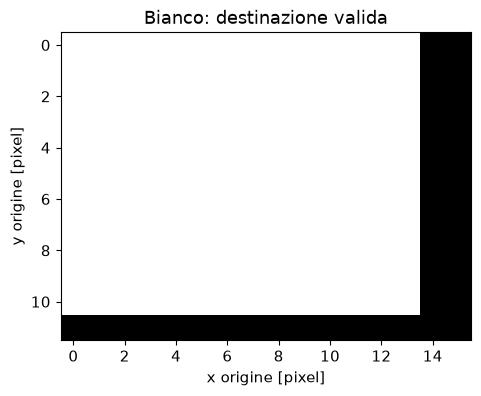

In [4]:
H,W=12,16; image1=rng.uniform(size=(H,W)); image2=np.zeros_like(image1)
image2[1:,2:]=image1[:-1,:-2]
y,x=np.mgrid[:H,:W]; valid=(x+2<W)&(y+1<H)
warped=image2[y[valid]+1,x[valid]+2]
warp_error=np.max(np.abs(warped-image1[valid]))
flow_true=np.array([2.,1.]); flow_pred=np.array([1.,1.]); resized=.5*flow_true
A=np.array([[1.,0.],[2.,0.],[3.,0.]]); b=np.array([2.,4.,6.])
v0=np.linalg.lstsq(A,b,rcond=None)[0]
A1=np.vstack([A,[0.,1.]]); b1=np.r_[b,1.]; v1=np.linalg.lstsq(A1,b1,rcond=None)[0]
flow={'pixel_validi':int(valid.sum()),'errore_warp_max':warp_error,
      'EPE_pixel':np.linalg.norm(flow_pred-flow_true),'flow_ridotto':resized,
      'autovalori_normale':np.linalg.eigvalsh(A.T@A),'soluzione_norma_minima':v0,'soluzione_con_vincolo':v1}
assert valid.sum()==154 and warp_error==0
assert np.allclose(v1,[2,1])
print(flow); salva_json('flow.json',flow)
fig,ax=plt.subplots(); ax.imshow(valid,cmap='gray',vmin=0,vmax=1);ax.set(xlabel='x origine [pixel]',ylabel='y origine [pixel]',title='Bianco: destinazione valida');fig.savefig(output/'validita_flow.png',dpi=180,bbox_inches='tight');plt.show()


### Interpretazione

N12.C.1 — Spiegare 154 pixel validi, EPE e trasformazione del flow dimezzando la griglia.

N12.C.2 — Perché la pseudoinversa restituisce v=0 senza avere osservato il moto verticale?

## Conservare e interpretare gli output

Controllare i file nella cartella di output e scaricarli insieme al notebook se si usa un runtime temporaneo. JSON e CSV distinguono valori analitici assegnati, campioni sintetici e risultati dei calcoli. Le verifiche numeriche non stimano le prestazioni dei modelli reali. Per studiarli occorrono pesi, dati, licenze e un protocollo separato.

## Risorse primarie e implementazioni ufficiali

- [U-Net, articolo originale](https://arxiv.org/abs/1505.04597)

- [DPT, codice degli autori](https://github.com/isl-org/DPT)

- [RAFT, codice degli autori](https://github.com/princeton-vl/RAFT)